## Getting started with MPR_Tools

MPR_Tools is a python package developed for modeling Magnetic Particle Recoil (MPR) nuclear spectrometers. MPR_Tools contains methods useful for assessing the design of the magnetic fields, optimizing conversion foil and aperture geometry, generating synthetic measurements, and more. 

The module is built around a spectrometer object, which itself is composed of subobjects like the ConversionFoil and hodoscope objects. In the following cells, a spectrometer object is created step by step.

# Conversion Foil and Aperture

A spectrometer object is composed of several sub-objects. The first of these is the ConversionFoil. Conversion foil is defined by several geometric parameters and choice of conversion foil material.

```text
 |                                    |    |	  	    	
 |                      aperture      |____|	  		
_|         foil            |				  		
_- - - - n ->|  ->  p  ->   -> ... into the magnet system			
 |  incident      recoil   |           ____
 |  radiation     particle            |    |
 |                                    |    |	  		
 ```

In [2]:
import MPR_Tools.MPR_Tools as mprt
import numpy as np
import matplotlib.pyplot as plt

#Define conversion and acceptance geometry
r_foil = 1.5 # cm       # Conversion foil radius - assumes circular foil
                        #      Note: foil shape can be toggled to rectangular
L = 50 # cm             # Distance from foil to aperture
T = 150 # um            # Thickness of conversion foil
r_aperture = 1.75 # cm  # aperture radius

# Create the MPR_Tools foil object
foil = mprt.ConversionFoil(foil_radius=r_foil, thickness=T, aperture_distance=L, aperture_radius=r_aperture, foil_material='CH2', aperture_type='circ')


Initializing conversion foil...
Loaded SRIM data from CH2srimdata.txt
Loaded cross sections from c:\Users\smackie\Desktop\Research\MPR_Tools_DEMO\MPR_Tools\MPR_Tools\data\np_crosssection.txt
Loaded differential scattering data from c:\Users\smackie\Desktop\Research\MPR_Tools_DEMO\MPR_Tools\MPR_Tools\data\np_diffxs.txt
Loaded cross sections from c:\Users\smackie\Desktop\Research\MPR_Tools_DEMO\MPR_Tools\MPR_Tools\data\nC12_crosssection.txt
Conversion foil initialization complete.



The ConversionFoil object handles computations related to recoil particle generation. Using a Monte Carlo method, you can calculate the conversion efficiency for a given geometry and generate ensembles of scattered particles that enter the aperture. These recoil populations can be generated by specifying the number of particles and the incident neutron spectrum (as arrays of energies and corresponding probabilities). 

The conversion foil geometry can also be changed using setter methods allowing for analysis of the trade off between efficiency and resolution.


Estimating intrinsic efficiency for 14.100 MeV particles using 4 processes...


Calculating geometric acceptance: 100%|██████████| 10000/10000 [00:04<00:00, 2397.73it/s]


Processed 10000 samples using 4 processes
Scattering efficiency: 8.61e-04
Geometric efficiency: 1.25e-03
Total efficiency: 1.08e-06


Calculating proton energy distribution...: 100%|██████████| 10000/10000 [00:03<00:00, 2834.76it/s]



Estimating intrinsic efficiency for 14.100 MeV particles using 4 processes...


Calculating geometric acceptance: 100%|██████████| 10000/10000 [00:04<00:00, 2400.70it/s]


Processed 10000 samples using 4 processes
Scattering efficiency: 2.87e-04
Geometric efficiency: 1.25e-03
Total efficiency: 3.60e-07


Calculating proton energy distribution...: 100%|██████████| 10000/10000 [00:03<00:00, 2783.07it/s]


Efficiency ratio (150 um / 50 um): 3
150 um: n=10000, mean=13.802 MeV, std=0.16652 MeV, 5–95% range=13.545–14.059 MeV
50 um: n=10000, mean=13.995 MeV, std=0.055389 MeV, 5–95% range=13.908–14.08 MeV


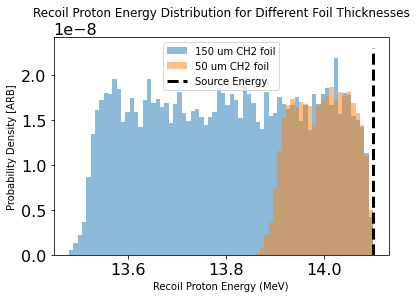

In [3]:
# The foil object can be used to calculate the intrinsic efficiency from cross section data and geometry

# The foil object determines the efficiency (assuming perfect transmission through the magnets)
# calculate_efficiency returns a tuple of efficiency factors, the final element is the total efficiency
foil.set_thickness(150)
eps_150um=foil.calculate_efficiency(14.1, 10000, max_workers=4)[-1] # set max workers to reduce set up overhead for parallelism

# Generate recoil particle distribution for a monoenergetic 14.1 MeV source
E = np.r_[14.1]
fn = np.r_[1.]
fp_150um = foil.get_recoil_energy_distribution(E, fn, 10000)  #returns a list of accepted particle energies for the given source energy and distribution

# the foil geometry can be accessed and modified using getter and setter methods
foil.set_thickness(50) # set foil thickness to 50 um

eps_50um = foil.calculate_efficiency(14.1, 10000, max_workers=4)[-1]
fp_50um = foil.get_recoil_energy_distribution(E, fn, 10000)

print(f"Efficiency ratio (150 um / 50 um): {eps_150um / eps_50um:.3g}")
for label, samples in [('150 um', fp_150um), ('50 um', fp_50um)]:
    print(
        f"{label}: n={samples.size}, mean={samples.mean():.5g} MeV, "
        f"std={samples.std():.5g} MeV, "
        f"5–95% range={np.quantile(samples, 0.05):.5g}–"
        f"{np.quantile(samples, 0.95):.5g} MeV"
    )

# Use common bins so the two distributions can be compared directly
bin_edges = np.linspace(
    min(fp_150um.min(), fp_50um.min()),
    max(fp_150um.max(), fp_50um.max()),
    71,
)

fig, ax = plt.subplots()
# Distribute each foil's total efficiency evenly across its sampled particles
weights_150um = np.full(fp_150um.shape, eps_150um / fp_150um.size)
weights_50um = np.full(fp_50um.shape, eps_50um / fp_50um.size)

ax.hist(
    fp_150um, bins=bin_edges, weights=weights_150um, alpha=0.5,
    label='150 um CH2 foil',
)
ax.hist(
    fp_50um, bins=bin_edges, weights=weights_50um, alpha=0.5,
    label='50 um CH2 foil',
)

ax.vlines(14.1, 0, max(ax.get_ylim()), color='k', linestyle='--', label='Source Energy')
ax.set_xlabel('Recoil Proton Energy (MeV)')
ax.set_ylabel('Probability Density [ARB]')
ax.set_title('Recoil Proton Energy Distribution for Different Foil Thicknesses')
ax.legend()

# Hodoscope

The next sub-object to construct is the hodoscope. It is composed of various detector channels that can be configured in different ways. The simplest is to pass the geometry of a single channel and the number of channels to the left and right of the reference energy channel. This is cumbersome for more complicated geometries, so you can also define the hodoscope from a csv file that contains the width and height of each channel.

In [4]:
# initialize the hodoscope

# hodoscope can be initialized manually, or from file. Here we generate the hodoscope object from a .csv file
# Sets the number of channels and specifies the rectangular bounds (height and width) of each
hodoscope = mprt.Hodoscope(channels='hodo_input.csv')


# There are methods for determining the channel for a given position, among other things.
print(f"The position x=-20 cm is in channel {hodoscope.get_channel_for_position(-.20)}")

The position x=-20 cm is in channel 7


# The MPR Spectrometer itself!

The spectrometer object is constructed from the foil object and hodoscope object, as well as additional data about the magnets; namely, the reference energy and energy bite and the ion optical transfer map.

The transfer map is the central data that defines the quality of the spectrometer. The formatting is assumed to be that of COSY INFINITY output such that the last column contains the exponents abcde of each term in the map of the form x^a * theta_x^b * y^c * theta_y^d * delta_e^e.

The transfer map is used to transport particles through the magnet systems to the focal plane. It can be of arbitrary order. A class method for applying the transfer map up to a specified order is implemented in spectrometer. Each input ray generated (see below) is passed through the Taylor map to calculate the ray trajectory as the particle passes through the focal plane.



In [5]:
# set up the spectrometer object

E0 = 16 # MeV           # Nominal central energy of the spectrometer
E_bite = 0.25 # nominal bite as fraction of E0
map_path = "./transfermaps/NSPC_thesis_5.txt" # path to ion optical transfer map

NSPC = mprt.MPRSpectrometer(foil, map_path, E0, E0*(1-E_bite), E0*(1+E_bite), hodoscope, 'figs')

system_parameters = NSPC.get_system_summary() # gathers relevant system parameters
for key, value in system_parameters.items():
    print(f"{key}: {value}")



Initializing Magnetic Proton Recoil Spectrometer...
Loaded COSY transfer map from ./transfermaps/NSPC_thesis_5.txt

MPR spectrometer initialization complete.

foil_radius_cm: 1.5
foil_thickness_um: 49.99999999999999
aperture_distance_cm: 50.0
aperture_type: circ
particle: proton
reference_energy_MeV: 16
min_energy: 12.0
max_energy: 20.0
hodoscope_channels: 40
detector_width_cm: 54.699999999999996
num_input_recoil_particles: 0
num_output_recoil_particles: 0
aperture_radius_cm: 1.7500000000000002


There are two methods of generating particles: a characteristic ray method for ion optical optimization, and a monte carlo method suitable for realistic response function calculations. In either case, a set of particle vectors is generated following the conventions of COSY INFINITY. In the code this is implemented as a 2D array spectrometer.input_beam which stores the N generated particles' phase space coordinates. 

Next, the input beam is transformed into the output beam in the focal plane by applying the transfer map using spectrometer.apply_transfer_map. The map can be of arbitrary order, and the method can set the order to any order less than that of the map itself (eg you can make 3rd order calculations with a 5th order map).

We will first explore 2 applications of the monte carlo generation method: understanding the energy-dependent spectrometer response function, and generating synthetic measurements from a given neutron spectrum.

Generating 100000 Monte Carlo proton trajectories using 4 processes...


Generating Monte Carlo proton trajectories: 100%|██████████| 100000/100000 [00:29<00:00, 3368.22it/s]


Input beam saved to figs/data/input_beam.csv
Applying order 5 transfer map to 100000 protons using 16 processes...


Applying order 5 transfer map: 100%|██████████| 4032/4032 [00:17<00:00, 228.35it/s]


Transfer map applied successfully!
Output beam saved to figs/data/output_beam.csv


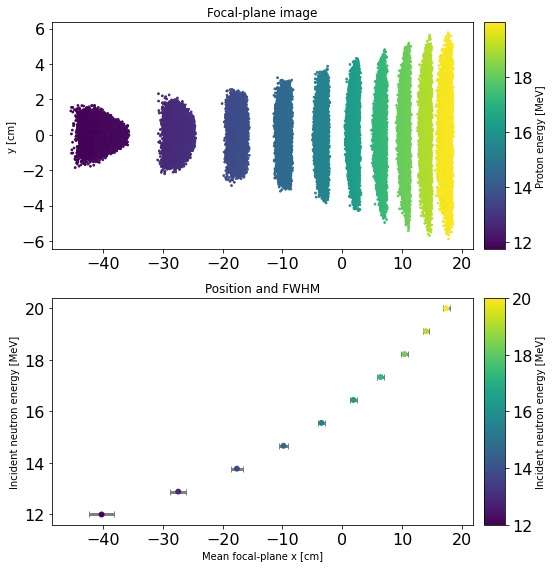

In [11]:
# Monte Carlo generation

# First look at a set of monoenergetic incident neutron beam energies, and generate the corresponding recoil proton distributions
E_n = np.linspace(12, 20, 10) # set of energies in MeV
f_n = np.ones_like(E_n) / E_n.size # uniform distribution of energy

NSPC.generate_monte_carlo_rays(
    incident_energies=E_n,
    probability_distribution=f_n,
    num_recoil_particles=100000,
    max_workers=4,
    continuous_energy_sampling=False,
) # generate rays at the discrete energies in E_n
NSPC.apply_transfer_map()

means = np.zeros_like(E_n)
fwhms = np.zeros_like(E_n)

# The input and output beams retain matching row order; input column 6 is incident neutron energy.
incident_energies = NSPC.input_beam[:, 6]
focal_x = NSPC.output_beam[:, 0] * 100  # convert metres to cm
for i, energy in enumerate(E_n):
    energy_mask = np.isclose(incident_energies, energy)
    positions = focal_x[energy_mask]
    if positions.size < 2:
        raise ValueError(f"Need at least two recoil particles at {energy:.3f} MeV; got {positions.size}.")

    means[i] = np.mean(positions)
    fwhms[i], _ = mprt.PerformanceAnalyzer.fwfm(positions, fractional_max=0.5)

fig = plt.figure(figsize=(8, 8))
grid = fig.add_gridspec(2, 2, width_ratios=(1, 0.05))
ax = fig.add_subplot(grid[0, 0])
ax_energy = fig.add_subplot(grid[1, 0], sharex=ax)
cax = fig.add_subplot(grid[0, 1])
cax_energy = fig.add_subplot(grid[1, 1])

proton_energies = NSPC.reference_energy * (1 + NSPC.output_beam[:, 5])
image = ax.scatter(
    focal_x,
    NSPC.output_beam[:, 2] * 100,
    c=proton_energies,
    cmap='viridis',
    s=3,
)
ax.set(ylabel='y [cm]', title='Focal-plane image')
fig.colorbar(image, cax=cax, label='Proton energy [MeV]')

ax_energy.errorbar(means, E_n, xerr=fwhms / 2, fmt='none', ecolor='0.5', capsize=3)
energy_points = ax_energy.scatter(means, E_n, c=E_n, cmap='viridis', s=24, zorder=3)
ax_energy.set(xlabel='Mean focal-plane x [cm]', ylabel='Incident neutron energy [MeV]', title='Position and FWHM')
fig.colorbar(energy_points, cax=cax_energy, label='Incident neutron energy [MeV]')
fig.tight_layout()


A data set like this can be used to calculate the spectrometer's resolution. The resolution of an ion optical spectrometer like this is defined as the ratio of the ion optical image size (FWHM in dispersive direction) to the magnetic dispersion (dx/dE). Because the spectrometer response is heteroskedastic (the statistical properties vary with the independent variable ie the incident energy), both the image size and dispersion must be evaluated across the energy bite to fully characterize the instrument. The cell below demonstrates the principle behind the spectrometer PerformanceAnalyzer class method generate_performance_curve.

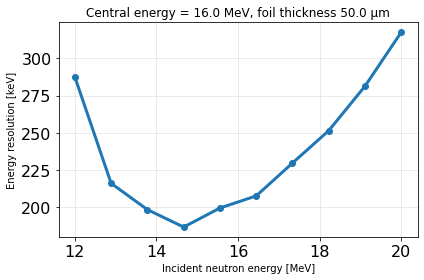

In [16]:
dxdE = np.gradient(means, E_n*1000)
delta_x = fwhms

Resolution = delta_x / dxdE

fig, ax = plt.subplots()
ax.plot(E_n, Resolution, marker='o')
ax.set(
    xlabel='Incident neutron energy [MeV]',
    ylabel='Energy resolution [keV]',
    title=f'Central energy = {NSPC.reference_energy:.1f} MeV, foil thickness {NSPC.conversion_foil.thickness * 1e6:.1f} μm',
)
ax.grid(True, alpha=0.3)
fig.tight_layout()

The other major use of the Monte Carlo ray method is to generate synthetic data from a given neutron spectrum. In the cell below, the Brysk '73 analytic model is used to construct a thermal emission spectrum from a given temperature. It is straightforward to read in simulated spectra instead.

We can then use the Performance analyzer object to bin the response according to the hodoscope bins. The analyzer object can perform quite sophisticated analysis routines that factor in detector response and background levels if additional data is provided. But for this simple example we just consider the counts per recoil particle in each channel.

Generating 100000 Monte Carlo proton trajectories using 4 processes...


Generating Monte Carlo proton trajectories: 100%|██████████| 100000/100000 [00:32<00:00, 3098.94it/s]


Input beam saved to figs/data/input_beam.csv
Applying order 5 transfer map to 100000 protons using 16 processes...


Applying order 5 transfer map: 100%|██████████| 4032/4032 [00:15<00:00, 257.88it/s]


Transfer map applied successfully!
Output beam saved to figs/data/output_beam.csv


c:\Users\smackie\Desktop\Research\MPR_Tools_DEMO\MPR_Tools\MPR_Tools\analysis\performance.py:351: RuntimeWarning: Performance curve file comprehensive_performance.csv not found. May need to generate first.
  warnings.warn(f'Performance curve file {performance_curve_file} not found. May need to generate first.', RuntimeWarning)
c:\Users\smackie\Desktop\Research\MPR_Tools_DEMO\MPR_Tools\MPR_Tools\analysis\performance.py:600: RuntimeWarning: invalid value encountered in divide
  coverage_per_bin = np.where(total_per_bin > 0, signal_per_bin / total_per_bin, 0.0)


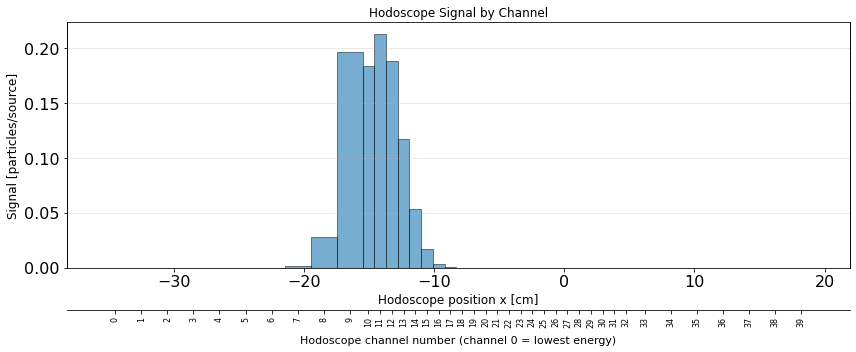

In [21]:
Ti = 5 # keV

En = np.linspace(12, 20, 100)


fwhm_keV = 177 * np.sqrt(Ti)
sigma_MeV = fwhm_keV / (2 * np.sqrt(2 * np.log(2)) * 1e3)
f_n = np.exp(-0.5 * ((En - 14.1) / sigma_MeV) ** 2)

NSPC.generate_monte_carlo_rays(
    incident_energies=En,
    probability_distribution=f_n,
    num_recoil_particles=100000,
    max_workers=4,
    continuous_energy_sampling=True,
)
NSPC.apply_transfer_map()

analyzer = mprt.PerformanceAnalyzer(NSPC)
channel_signal, _, _ = analyzer.get_recoil_x_map()
channel_edges_cm = NSPC.hodoscope.channel_edges * 100
signal_units = 'MeV deposited/source' if NSPC.hodoscope.detector_used else 'particles/source'

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(
    channel_edges_cm[:-1],
    channel_signal,
    width=np.diff(channel_edges_cm),
    align='edge',
    alpha=0.6,
    edgecolor='black',
    linewidth=0.8,
)
ax.set(
    xlabel='Hodoscope position x [cm]',
    ylabel=f'Signal [{signal_units}]',
    title='Hodoscope Signal by Channel',
)
ax.xaxis.label.set_size(12)
ax.yaxis.label.set_size(12)

channel_axis = ax.twiny()
channel_axis.set_xlim(ax.get_xlim())
channel_axis.spines['top'].set_visible(False)
channel_axis.spines['bottom'].set_position(('outward', 42))
channel_axis.xaxis.set_ticks_position('bottom')
channel_axis.xaxis.set_label_position('bottom')
channel_axis.set_xticks(NSPC.hodoscope.channel_centers * 100)
channel_axis.set_xticklabels(range(NSPC.hodoscope.total_channels), rotation=90, fontsize=8)
channel_axis.set_xlabel('Hodoscope channel number (channel 0 = lowest energy)', fontsize=11, labelpad=8)
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()



Characteristic rays are the other choice for generating particle sets. Characteristic rays span the energy range of the instrument with equal spacing, and are generated by considering the possible rays through polar grids in the foil and aperture. Thus, for each energy the characteristic ray method gives an understanding of the beam envelope. Furthermore, because the characteristic ray method is deterministic and embeds structure in the image, it is particularly usefule for ion optical optimization. Looking at maps of different orders can reveal aberrations and give insight into the required corrections (see S. Mackie et al 2024 in Review of Scientific Instruments). In the below cell, the characteristic ray method is used to identify an aberration in an unoptimized map and then the optimized map is used to verify the aberation has been removed.

Characteristic ray energy range: 12.000-20.000 MeV


Generating 768 characteristic rays...: 3it [00:01,  2.02it/s]


Generated 243 unique rays
Found 525 duplicate rays
Applying order 5 transfer map to 768 protons using 4 processes...


Applying order 5 transfer map: 100%|██████████| 224/224 [00:04<00:00, 47.93it/s]


Transfer map applied successfully!
Output beam saved to figs/data/output_beam.csv
Characteristic ray energy range: 12.000-20.000 MeV


Generating 768 characteristic rays...: 3it [00:01,  1.98it/s]


Generated 243 unique rays
Found 525 duplicate rays
Applying order 5 transfer map to 768 protons using 4 processes...


Applying order 5 transfer map: 100%|██████████| 224/224 [00:04<00:00, 53.89it/s]


Transfer map applied successfully!
Output beam saved to figs/data/output_beam.csv
Unoptimized total x width: 60.436 cm
Optimized total x width:   56.612 cm
Width change: -3.824 cm (-6.3%)


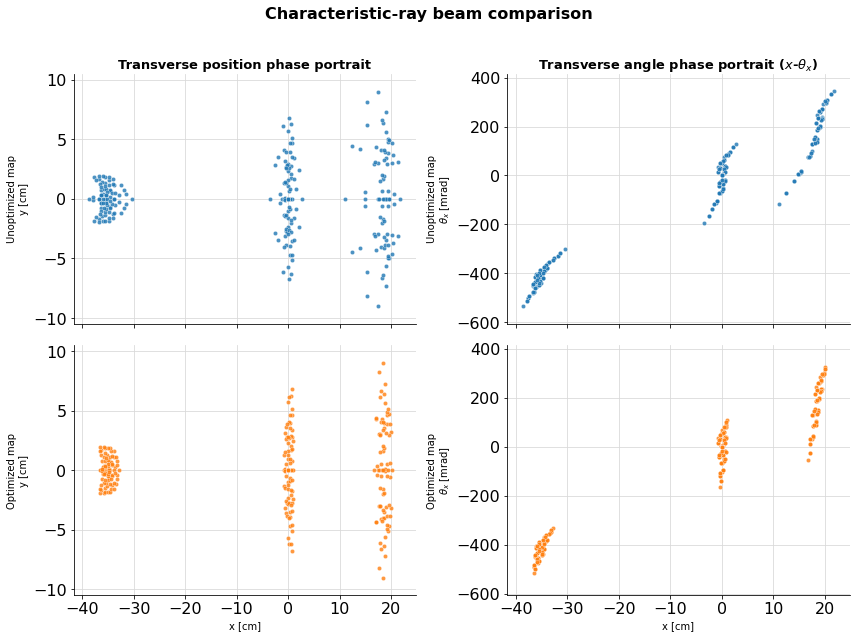

In [24]:
ray_settings = {
    'radial_points': 1,
    'angular_points': 8,
    'aperture_radial_points': 1,
    'aperture_angular_points': 8,
    'energy_points': 1,
    'min_energy': 12,
    'max_energy': 20,
}

# Generate matching characteristic rays for both transfer maps.
NSPC.transfer_map = np.genfromtxt('./transfermaps/NSPC_thesis_3_uncorrected.txt', unpack=True)
NSPC.generate_characteristic_rays(**ray_settings)
NSPC.apply_transfer_map(max_workers=4)
unoptimized_beam = NSPC.output_beam.copy()

NSPC.transfer_map = np.genfromtxt('./transfermaps/NSPC_thesis_3_corrected.txt', unpack=True)
NSPC.generate_characteristic_rays(**ray_settings)
NSPC.apply_transfer_map(max_workers=4)
optimized_beam = NSPC.output_beam.copy()

unoptimized_x = unoptimized_beam[:, 0] * 100  # m to cm
optimized_x = optimized_beam[:, 0] * 100  # m to cm
unoptimized_width = np.ptp(unoptimized_x)
optimized_width = np.ptp(optimized_x)
width_change = optimized_width - unoptimized_width
width_change_percent = 100 * width_change / unoptimized_width if unoptimized_width else 0.0

print(f'Unoptimized total x width: {unoptimized_width:.3f} cm')
print(f'Optimized total x width:   {optimized_width:.3f} cm')
print(f'Width change: {width_change:+.3f} cm ({width_change_percent:+.1f}%)')

beams = (unoptimized_beam, optimized_beam)
x_positions = (unoptimized_x, optimized_x)
y_positions = tuple(beam[:, 2] * 100 for beam in beams)  # m to cm
theta_x = tuple(beam[:, 1] * 1000 for beam in beams)  # relative angle to mrad

x_min = min(values.min() for values in x_positions)
x_max = max(values.max() for values in x_positions)
x_padding = 0.05 * (x_max - x_min) or 0.1

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex='col', sharey='col')
plot_rows = (
    ('Unoptimized map', unoptimized_x, y_positions[0], theta_x[0], 'tab:blue'),
    ('Optimized map', optimized_x, y_positions[1], theta_x[1], 'tab:orange'),
)

for row, (map_label, x, y, angle, color) in enumerate(plot_rows):
    axes[row, 0].scatter(x, y, s=18, color=color, alpha=0.8, edgecolors='white', linewidths=0.35)
    axes[row, 1].scatter(x, angle, s=18, color=color, alpha=0.8, edgecolors='white', linewidths=0.35)
    axes[row, 0].set_ylabel(f'{map_label}\ny [cm]')
    axes[row, 1].set_ylabel(f'{map_label}\n' + r'$\theta_x$ [mrad]')

axes[0, 0].set_title('Transverse position phase portrait', fontsize=13, weight='bold')
axes[0, 1].set_title(r'Transverse angle phase portrait ($x$-$\theta_x$)', fontsize=13, weight='bold')
axes[1, 0].set_xlabel('x [cm]')
axes[1, 1].set_xlabel('x [cm]')

for ax in axes.flat:
    ax.set_xlim(x_min - x_padding, x_max + x_padding)
    ax.grid(True, color='0.85', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

for column, values in enumerate((y_positions, theta_x)):
    y_min = min(data.min() for data in values)
    y_max = max(data.max() for data in values)
    y_padding = 0.08 * (y_max - y_min) or 0.1
    axes[0, column].set_ylim(y_min - y_padding, y_max + y_padding)

fig.suptitle('Characteristic-ray beam comparison', fontsize=16, weight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.96))

This notebook has given you a taste of what MPR_Tools can do! Consider adding your own example use cases to the repo as you add capabilities and build your own analysis routines. 